# Customers Like You — Analysis (ML1–ML6)

Run `python src/build_matrix.py` first; this notebook reads its output from `data/processed/`.

In [1]:
from pathlib import Path
import os, time, tracemalloc
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

if not Path("src").exists():
    os.chdir("..")  # run from the repository root
SEED = 42
DATA = Path("data/processed")
Path("figures").mkdir(exist_ok=True)

A = sp.load_npz(DATA / "A_log.npz").tocsr()
train = pd.read_pickle(DATA / "train.pkl")
products = pd.read_csv(DATA / "products.csv", dtype={"StockCode": str})
customers = pd.read_csv(DATA / "customers.csv")
cust_idx = pd.Series(customers["idx"].to_numpy(), index=customers["Customer ID"])
prod_idx = pd.Series(products["idx"].to_numpy(), index=products["StockCode"])
test_targets = pd.read_csv(DATA / "test_targets.csv").groupby("cust_idx")["prod_idx"].apply(set)
print(f"Matrix {A.shape[0]:,} x {A.shape[1]:,}; test customers to score: {len(test_targets):,}")

Matrix 5,471 x 3,686; test customers to score: 1,913


## ML1 — Method choice (written before fitting)

**Main method: Truncated SVD.**

- The matrix is about 98% zeros. Truncated SVD works on the sparse matrix directly. PCA has to centre every column first, which turns the zeros into small negative numbers. A dense 161 MB matrix instead of 5 MB.
- One SVD fit gives both product factors and customer factors.

PCA is run on the same matrix with the same k in ML5 for comparison.

## Shared functions

In [ ]:
def matrix_from(rows):
    """Customer x product matrix (log(1 + quantity)) with the same rows and columns as A."""
    rows = rows[rows["StockCode"].isin(prod_idx.index) & rows["Customer ID"].isin(cust_idx.index)]
    q = rows.groupby(["Customer ID", "StockCode"])["Quantity"].sum().reset_index()
    return sp.csr_matrix((np.log1p(q["Quantity"].to_numpy(dtype=float)),
                          (q["Customer ID"].map(cust_idx), q["StockCode"].map(prod_idx))), shape=A.shape)

def new_purchases(before, after, A_before):
    """Purchases in `after` of products the customer never bought in `before`."""
    seen = before[["Customer ID", "StockCode"]].drop_duplicates()
    pairs = after[["Customer ID", "StockCode"]].drop_duplicates()
    pairs = pairs[pairs["Customer ID"].isin(cust_idx.index) & pairs["StockCode"].isin(prod_idx.index)]
    new = pairs.merge(seen, how="left", indicator=True)
    new = new[new["_merge"] == "left_only"]
    t = pd.DataFrame({"c": new["Customer ID"].map(cust_idx), "p": new["StockCode"].map(prod_idx)})
    t = t[np.diff(A_before.indptr)[t["c"]] > 0]  # customer history
    return t.groupby("c")["p"].apply(set)

def hit_rate(score, A_fit, targets, n=10):
    """Share of customers with at least one target product in their top n."""
    rows = targets.index.to_numpy()
    X = A_fit[rows]
    S = np.asarray(score(X), dtype=float)
    S[X.toarray() > 0] = -np.inf  # never recommend what already bought
    top = np.argpartition(-S, n, axis=1)[:, :n]
    return np.mean([len(targets[r] & set(t)) > 0 for r, t in zip(rows, top)])

def best_sellers(A_fit):
    """Baseline: the 10 products bought by the most customers."""
    pop = np.asarray((A_fit > 0).sum(axis=0)).ravel().astype(float)
    return lambda X: np.tile(pop, (X.shape[0], 1))

def svd_scores(model):
    """Score = sum over bought products of factor similarity = x V V^T."""
    V = model.components_.T
    return lambda X: (X @ V) @ V.T

def rel_error(model, M):
    """||M - M_k||_F / ||M||_F from the kept singular values."""
    return np.sqrt(1 - (model.singular_values_ ** 2).sum() / (M.data ** 2).sum())

## ML2 — Choosing k

Reconstruction error is measured on the full training matrix. To choose k without touching the test set (R2), the last two months of the *training* period (from 2011-08-09) are used as a validation window: fit on purchases before it, score new purchases inside it.

In [3]:
VAL_START = pd.Timestamp("2011-08-09")
fit_rows = train[train["InvoiceDate"] < VAL_START]
val_rows = train[train["InvoiceDate"] >= VAL_START]
A_fit = matrix_from(fit_rows)
val_targets = new_purchases(fit_rows, val_rows, A_fit)

rows = []
for k in [10, 20, 50, 100, 200]:
    full = TruncatedSVD(k, random_state=SEED).fit(A)
    val = TruncatedSVD(k, random_state=SEED).fit(A_fit)
    rows.append({"k": k, "relative error": rel_error(full, A),
                 "validation hit@10": hit_rate(svd_scores(val), A_fit, val_targets)})
sweep = pd.DataFrame(rows)
val_baseline = hit_rate(best_sellers(A_fit), A_fit, val_targets)
K = int(sweep.loc[sweep["validation hit@10"].idxmax(), "k"])
print(f"Validation customers: {len(val_targets):,}; best-seller baseline: {val_baseline:.3f}")
print(sweep.round(3).to_string(index=False))
print("Chosen k =", K)

Validation customers: 1,423; best-seller baseline: 0.252
  k  relative error  validation hit@10
 10           0.876              0.313
 20           0.846              0.344
 50           0.790              0.361
100           0.728              0.379
200           0.639              0.360
Chosen k = 100


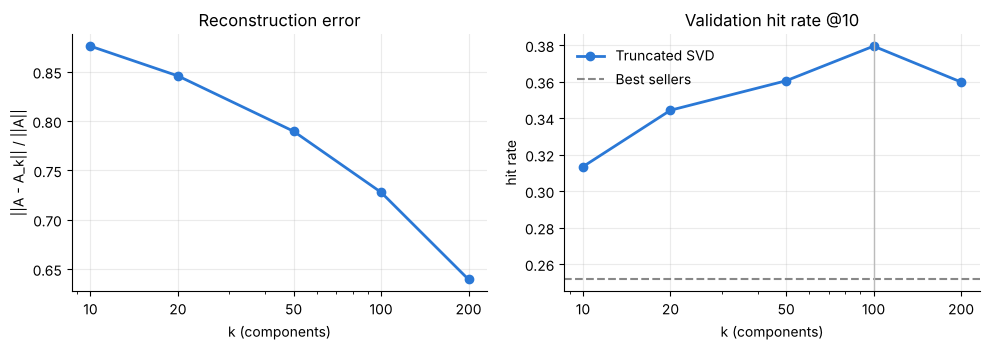

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(sweep["k"], sweep["relative error"], marker="o", color="#2a78d6", lw=2)
ax1.set(title="Reconstruction error", xlabel="k (components)", ylabel="||A - A_k|| / ||A||")
ax2.plot(sweep["k"], sweep["validation hit@10"], marker="o", color="#2a78d6", lw=2, label="Truncated SVD")
ax2.axhline(val_baseline, color="#888888", ls="--", lw=1.5, label="Best sellers")
ax2.axvline(K, color="#bbbbbb", lw=1)
ax2.set(title="Validation hit rate @10", xlabel="k (components)", ylabel="hit rate")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.set_xscale("log"); ax.set_xticks(sweep["k"]); ax.set_xticklabels(sweep["k"])
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig("figures/k_curve.png", dpi=150); plt.show()

The error keeps falling as k grows, so it has no clear elbow. The validation hit rate peaks at the chosen k and then drops (more components start fitting noise), so k is set where recommendations are best.

## ML3 — Recommendations

In [5]:
svd = TruncatedSVD(K, random_state=SEED).fit(A)
P = normalize(svd.components_.T)  # one unit-length vector per product

def similar(stock_code, n=10):
    """Product page box: the n products with the highest cosine similarity."""
    j = prod_idx[stock_code]
    s = P @ P[j]
    s[j] = -np.inf
    top = np.argsort(-s)[:n]
    return products.loc[top, ["StockCode", "Description"]].assign(similarity=s[top].round(3))

def recommend(c, n=10):
    """Top n products for customer row c, excluding what they already bought."""
    x = A[c]
    s = svd_scores(svd)(x).ravel()
    s[x.indices] = -np.inf
    return products.loc[np.argsort(-s)[:n], ["StockCode", "Description"]]

example = products.loc[prod_idx["85099B"]]  # red spotty jumbo bag
print("Customers who bought", example["Description"].strip(), "also bought:")
similar(example["StockCode"])

Customers who bought JUMBO BAG RED WHITE SPOTTY also bought:


,StockCode,Description,similarity
3413,85099F,JUMBO BAG STRAWBERRY,0.660
3412,85099C,JUMBO BAG BAROQUE BLACK WHITE,0.607
1447,22386,JUMBO BAG PINK WITH WHITE SPOTS,0.601
1065,21929,JUMBO BAG PINK VINTAGE PAISLEY,0.343
1466,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,0.308
1064,21928,JUMBO BAG SCANDINAVIAN PAISLEY,0.296
1072,21936,RED/WHITE SPOT PICNIC BAG,0.262
1438,22377,BOTTLE BAG RETROSPOT,0.248
3322,85018A,S/6 PAPER BOXES ROMANTIC IMAGES,0.235
179,20711,JUMBO BAG TOYS,0.229


## ML4 — Evaluation on held-out test purchases

In [6]:
model_hit = hit_rate(svd_scores(svd), A, test_targets)
base_hit = hit_rate(best_sellers(A), A, test_targets)

def nightly_job():
    """Fit, build the product-page table, and score every customer."""
    m = TruncatedSVD(K, random_state=SEED).fit(A)
    Pn = normalize(m.components_.T)
    neighbours = np.argsort(-(Pn @ Pn.T), axis=1)[:, 1:11]
    V = m.components_.T
    recs = []
    for start in range(0, A.shape[0], 1000):
        X = A[start:start + 1000]
        S = (X @ V) @ V.T
        S[X.toarray() > 0] = -np.inf
        recs.append(np.argpartition(-S, 10, axis=1)[:, :10])
    return neighbours, np.vstack(recs)

t = time.time(); nightly_job(); job_seconds = time.time() - t
factor_mb = (A.shape[0] + A.shape[1]) * K * 8 / 1e6
dense_mb = A.shape[0] * A.shape[1] * 8 / 1e6

results = pd.DataFrame({
    "Hit rate @10": [f"{model_hit:.1%}", f"{base_hit:.1%}"],
}, index=[f"Truncated SVD (k={K})", "Best-seller baseline"])
print(results.to_string())
print(f"\nTest customers scored: {len(test_targets):,}")
print(f"Nightly job (fit + product table + all customers): {job_seconds:.1f} s")
print(f"Stored factors: {factor_mb:.1f} MB vs dense matrix {dense_mb:.1f} MB ({dense_mb / factor_mb:.0f}x smaller)")

                      Hit rate @10
Truncated SVD (k=100)        38.3%
Best-seller baseline         27.0%

Test customers scored: 1,913
Nightly job (fit + product table + all customers): 1.0 s
Stored factors: 7.3 MB vs dense matrix 161.3 MB (22x smaller)


## ML5 — PCA vs Truncated SVD (same matrix, same k)

In [7]:
def measure(make):
    tracemalloc.start(); t = time.time()
    m = make().fit(A)
    secs = time.time() - t
    peak = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    return m, secs, peak

svd_m, svd_t, svd_mem = measure(lambda: TruncatedSVD(K, random_state=SEED))
pca_m, pca_t, pca_mem = measure(lambda: PCA(K, svd_solver="arpack", random_state=SEED))
pca_scores = lambda X: (X - pca_m.mean_) @ pca_m.components_.T @ pca_m.components_ + pca_m.mean_

pop = np.asarray((A > 0).sum(axis=0)).ravel()
for name, m in [("SVD", svd_m), ("PCA", pca_m)]:
    c1 = m.components_[0] * np.sign(m.components_[0].sum())
    print(f"{name} component 1: positive weight on {(c1 > 0).mean():.1%} of products, "
          f"correlation with product popularity {np.corrcoef(c1, pop)[0, 1]:.2f}")

err = rel_error(svd_m, A)
comparison = pd.DataFrame({
    "PCA": [K, f"{pca_t:.2f}", f"{pca_mem:.0f}", f"{factor_mb + A.shape[1] * 8 / 1e6:.1f}",
            f"{pca_m.explained_variance_ratio_.sum():.1%} of variance explained",
            f"{hit_rate(pca_scores, A, test_targets):.1%}", f"{base_hit:.1%}",
            "Buying more of the popular range than the average customer"],
    "Truncated SVD": [K, f"{svd_t:.2f}", f"{svd_mem:.0f}", f"{factor_mb:.1f}",
                      f"{err:.1%} relative reconstruction error ({1 - err**2:.1%} of the squared norm kept)",
                      f"{model_hit:.1%}", f"{base_hit:.1%}",
                      "Overall buying volume: every product weighted positively, best sellers most"],
}, index=["k used", "Fit time (seconds)", "Peak memory during fit (MB)", "Size of stored factors (MB)",
          "Variance explained or relative reconstruction error", "Hit rate at 10 on held-out purchases",
          "Best-seller baseline hit rate at 10", "What component 1 represents"])
pd.set_option("display.max_colwidth", None)
comparison

SVD component 1: positive weight on 100.0% of products, correlation with product popularity 0.94
PCA component 1: positive weight on 99.8% of products, correlation with product popularity 0.91


,PCA,Truncated SVD
k used,100,100
Fit time (seconds),0.72,0.43
Peak memory during fit (MB),15,18
Size of stored factors (MB),7.4,7.3
Variance explained or relative reconstruction error,44.9% of variance explained,72.8% relative reconstruction error (47.0% of the squared norm kept)
Hit rate at 10 on held-out purchases,38.5%,38.3%
Best-seller baseline hit rate at 10,27.0%,27.0%
What component 1 represents,Buying more of the popular range than the average customer,"Overall buying volume: every product weighted positively, best sellers most"


Both methods give almost the same hit rate, because 98% of the matrix is zero. The column means PCA subtracts are tiny, so centring barely changes the directions. PCA only stays cheap here because scikit-learn centres implicitly, centring the matrix itself would make it dense (161 MB). Truncated SVD gets the same result without that risk, which is why it stays the main model.

## ML6 — Customer map

Component 1 is overall buying volume, so big and small shops with the same taste would sit far apart. Dividing components 2 and 3 by component 1 keeps only *what kind* of products a customer leans towards. Customers are then grouped with k-means (4 groups) and each group is named from the products it buys much more often than average, and its countries. No customer IDs are shown.

In [8]:
Z = svd.transform(A)
# Fix the sign of each component so the axes read the same on every machine
anchors = {1: "85123A", 2: "85099B"}  # white hanging heart T-light holder, red spotty jumbo bag
for comp, code in anchors.items():
    if svd.components_[comp, prod_idx[code]] < 0:
        Z[:, comp] *= -1
Z[:, 0] *= np.sign(Z[:, 0].sum())
X2 = np.column_stack([Z[:, 1] / Z[:, 0], Z[:, 2] / Z[:, 0]])

km = KMeans(4, n_init=10, random_state=SEED).fit(X2)
labels = km.labels_

country = (train.groupby("Customer ID")["Country"].agg(lambda s: s.value_counts().index[0])
                .reindex(customers["Customer ID"]).to_numpy())
B = (A > 0).astype(float)
overall = np.asarray(B.mean(axis=0)).ravel()
desc = products["Description"].fillna("").str.strip().to_numpy()

segment_words = {
    "Bags & storage": ["JUMBO", "BAG", "STORAGE"],
    "Home & kitchen gifts": ["BOTTLE", "RECIPE", "RIBBON", "KITCHEN", "CAKE", "CHRISTMAS"],
    "Rustic home decor": ["HEART", "WICKER", "FRAME", "ZINC", "T-LIGHT"],
    "Kids & party": ["PAINT", "CRAYON", "SPACEBOY", "SPACE BOY", "CLAY", "CIRCUS", "BIRTHDAY"],
}
names = list(segment_words)
tops, match = [], np.zeros((4, len(names)))
for g in range(4):
    share = np.asarray(B[labels == g].mean(axis=0)).ravel()
    lift = np.where(share >= 0.15, share / overall, 0)  # bought by at least 15% of the group
    top = desc[np.argsort(-lift)[:10]]
    tops.append(top)
    match[g] = [sum(any(w in t for w in words) for t in top) for words in segment_words.values()]
_, assigned = linear_sum_assignment(-match)
segment = {g: names[assigned[g]] for g in range(4)}

profiles = pd.DataFrame([{
    "Segment": segment[g],
    "Customers": int((labels == g).sum()),
    "Top products (vs average)": "; ".join(t.title() for t in tops[g][:5]),
    "Top countries": ", ".join(f"{c} {p:.0%}" for c, p in
                               pd.Series(country[labels == g]).value_counts(normalize=True).head(3).items()),
} for g in range(4)])
profiles

,Segment,Customers,Top products (vs average),Top countries
0,Bags & storage,726,Jumbo Bag Apples; Jumbo Bag Owls; Jumbo Bag Spaceboy Design; Jumbo Bag Dolly Girl Design; Jumbo Bag Pink With White Spots,"United Kingdom 87%, Germany 3%, France 3%"
1,Home & kitchen gifts,2009,Red Spot Heart Hot Water Bottle; Scottie Dog Hot Water Bottle; Recipe Box Pantry Yellow Design; 6 Ribbons Rustic Charm; Home Building Block Word,"United Kingdom 96%, Germany 1%, Spain 0%"
2,Rustic home decor,1387,Wooden Frame Antique White; Zinc Metal Heart Decoration; White Hanging Heart T-Light Holder; Heart Of Wicker Large; Heart Of Wicker Small,"United Kingdom 97%, Cyprus 0%, France 0%"
3,Kids & party,1349,Mini Paint Set Vintage; Space Boy Birthday Card; Pack Of 12 Traditional Crayons; Traditional Modelling Clay; Spaceboy Lunch Box,"United Kingdom 80%, Germany 4%, France 4%"


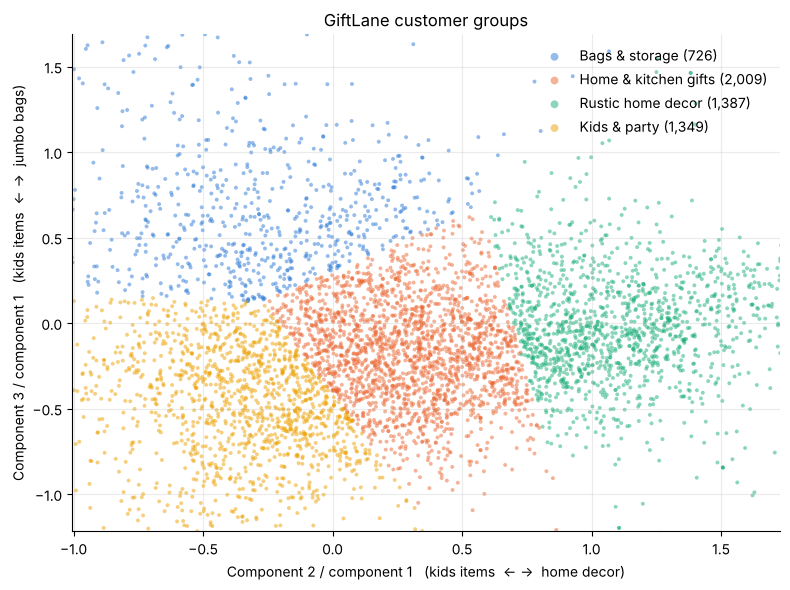

In [9]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(8, 6))
for g in range(4):
    m = labels == g
    ax.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.5, color=colors[g], edgecolors="none",
               label=f"{segment[g]} ({m.sum():,})")
lo, hi = np.percentile(X2, [1, 99], axis=0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
ax.set(title="GiftLane customer groups",
       xlabel="Component 2 / component 1   (kids items  ← →  home decor)",
       ylabel="Component 3 / component 1   (kids items  ← →  jumbo bags)")
ax.legend(frameon=False, markerscale=2, loc="best")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig("figures/customer_map.png", dpi=150); plt.show()